# Práctica 10. Oráculos y algoritmo de Deutsch–Jozsa

**Asignatura:** Computación cuántica    
**Modalidad:** Individual  
**Entorno:** Python y Qiskit

En esta práctica construiremos oráculos reversibles, implementaremos el algoritmo de Deutsch y lo generalizaremos al algoritmo de Deutsch–Jozsa.

> **Importante:** completa las celdas marcadas con `TODO` y responde de forma razonada a todas las preguntas. No se aceptará una entrega formada únicamente por código.


## Objetivos

Al finalizar la práctica serás capaz de:

- Clasificar funciones binarias como constantes o balanceadas.
- Construir oráculos reversibles con Qiskit.
- Verificar la acción de un oráculo sobre la base computacional.
- Implementar el algoritmo de Deutsch.
- Relacionar el retroceso de fase con la interferencia.
- Generalizar el procedimiento mediante Deutsch–Jozsa.
- Interpretar los resultados y comparar el número de consultas.


## Entrega

Antes de entregar, renombra el archivo como:

```text
10_oraculos_deutsch_jozsa_APELLIDOS_NOMBRE.ipynb
```

El notebook deberá incluir código ejecutado, circuitos, resultados, pruebas, respuestas razonadas y una conclusión final de entre 150 y 200 palabras.


## 1. Preparación del entorno

Ejecuta la siguiente celda. Si falta algún paquete, instálalo en el mismo entorno en el que se ejecuta Jupyter.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SEMILLA = 20
SHOTS = 1_000
simulador = AerSimulator()


In [2]:
import qiskit
import qiskit_aer

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)


Qiskit: 2.5.2
Qiskit Aer: 0.17.2




# Parte A. Funciones constantes y balanceadas

## Ejercicio 1. Clasificación de funciones

Considera una función de un bit:

$$
f:\{0,1\}\longrightarrow\{0,1\}.
$$

Una función es **constante** si $f(0)=f(1)$ y es **balanceada** si $f(0)\neq f(1)$.


In [3]:
def f0(x):
    return 0


def f1(x):
    return 1


def f2(x):
    return x


def f3(x):
    return 1 - x


funciones = {
    "f0": f0,
    "f1": f1,
    "f2": f2,
    "f3": f3,
}


Implementa `clasificar_funcion_un_bit(funcion)`. Debe comprobar que las salidas para 0 y 1 son bits válidos y devolver `"constante"` o `"balanceada"`.


In [64]:
def clasificar_funcion_un_bit(funcion):
    '''Clasifica una función binaria de un bit.'''
    # TODO: evalúa f(0) y f(1), valida las salidas y clasifica.
    if funcion(0) == funcion(1):
        return "Constante"
    else:
        return "Balanceada"


In [65]:
# TODO: completa y ejecuta la tabla.
for nombre, funcion in funciones.items():
    print(
        nombre,
        "f(0)=", funcion(0),
        "f(1)=", funcion(1),
        "tipo=", clasificar_funcion_un_bit(funcion),
    )


f0 f(0)= 0 f(1)= 0 tipo= Constante
f1 f(0)= 1 f(1)= 1 tipo= Constante
f2 f(0)= 0 f(1)= 1 tipo= Balanceada
f3 f(0)= 1 f(1)= 0 tipo= Balanceada


### Respuestas del ejercicio 1

1. ¿Cuántas evaluaciones necesita un algoritmo clásico determinista para garantizar la clasificación?
2. ¿Podría clasificar la función con certeza evaluando únicamente $f(0)$?
3. ¿Buscamos los valores individuales o una propiedad global de la función?

**Respuesta:**  
Escribe aquí tu respuesta.




# Parte B. Construcción de oráculos

## Ejercicio 2. Oráculos de Deutsch

El oráculo reversible debe implementar:

$$
U_f\lvert x,y\rangle=\lvert x,y\oplus f(x)\rangle.
$$

Utilizaremos `q[0]` como entrada $x$ y `q[1]` como auxiliar $y$.

| Tipo | Función | Implementación |
|---|---|---|
| `constante_0` | $f(x)=0$ | Identidad |
| `constante_1` | $f(x)=1$ | $X$ sobre el auxiliar |
| `balanceada_x` | $f(x)=x$ | CNOT |
| `balanceada_not_x` | $f(x)=1-x$ | CNOT y $X$ sobre el auxiliar |


In [66]:
def crear_oraculo_deutsch(tipo):
    '''Construye una puerta de dos qubits para el problema de Deutsch.'''
    oraculo = QuantumCircuit(2, name="U_f")

    # TODO: implementa los cuatro casos.
    # Si el tipo no es válido, lanza ValueError.
    if tipo == "constante_0":
        pass
    elif tipo == "constante_1":
        oraculo.x(1)
    elif tipo == "balanceada_x":
        oraculo.cx(0, 1)
    elif tipo == "balanceada_not_x":
        oraculo.cx(0, 1)
        oraculo.x(1)
    else:
        raise ValueError("Tipo de oráculo no válido")

    return oraculo.to_gate()


constante_0


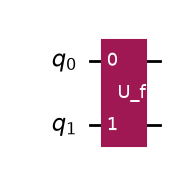

constante_1


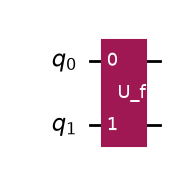

balanceada_x


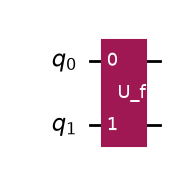

balanceada_not_x


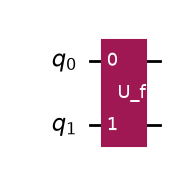

In [67]:
tipos_oraculo = [
    "constante_0",
    "constante_1",
    "balanceada_x",
    "balanceada_not_x",
]

# TODO: descomenta cuando hayas implementado crear_oraculo_deutsch().
for tipo in tipos_oraculo:
    circuito = QuantumCircuit(2)
    circuito.append(crear_oraculo_deutsch(tipo), [0, 1])
    print(tipo)
    display(circuito.draw("mpl"))


### Respuestas del ejercicio 2

1. ¿Por qué el oráculo utiliza dos qubits?
2. ¿Por qué no se implementa directamente $\lvert x\rangle\mapsto\lvert f(x)\rangle$?
3. ¿Qué qubit conserva la entrada?
4. ¿Qué operación clásica representa $\oplus$?
5. ¿Son reversibles los cuatro oráculos?

**Respuesta:**  
Escribe aquí tu respuesta.


## Ejercicio 3. Comprobación sobre la base computacional

Comprueba que los oráculos realizan correctamente:

$$
\lvert x,y\rangle\longrightarrow\lvert x,y\oplus f(x)\rangle.
$$

Recuerda que Qiskit muestra un estado de dos qubits con el orden $\lvert q_1q_0\rangle$.


In [68]:
def preparar_estado_base(x, y):
    '''Prepara |y x>, con q[0]=x y q[1]=y.'''
    # TODO: valida que x e y sean bits y prepara el estado.
    if x not in [0, 1] or y not in [0, 1]:
        raise ValueError("x e y deben ser bits (0 o 1)")
    circuito = QuantumCircuit(2)
    if x == 1:
        circuito.x(0)
    if y == 1:
        circuito.x(1)
    return circuito


In [69]:
def etiqueta_estado_base(estado, tolerancia=1e-10):
    '''Devuelve la etiqueta del estado base cuya probabilidad es 1.'''
    # TODO: calcula las probabilidades y localiza el índice no nulo.
    pass



Oráculo: constante_0


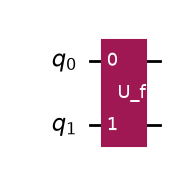

<IPython.core.display.Latex object>

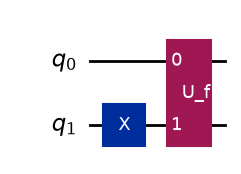

<IPython.core.display.Latex object>

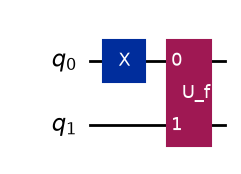

<IPython.core.display.Latex object>

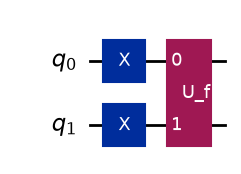

<IPython.core.display.Latex object>


Oráculo: constante_1


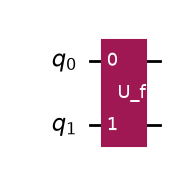

<IPython.core.display.Latex object>

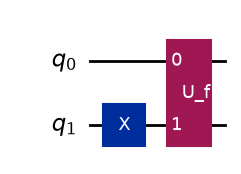

<IPython.core.display.Latex object>

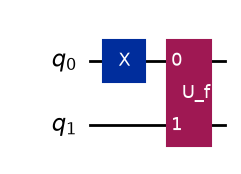

<IPython.core.display.Latex object>

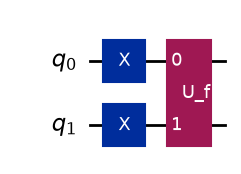

<IPython.core.display.Latex object>


Oráculo: balanceada_x


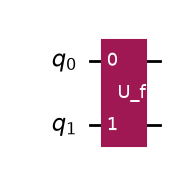

<IPython.core.display.Latex object>

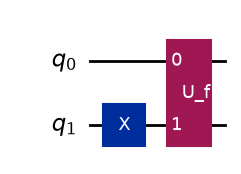

<IPython.core.display.Latex object>

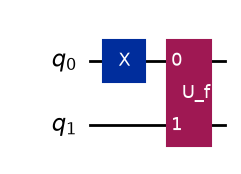

<IPython.core.display.Latex object>

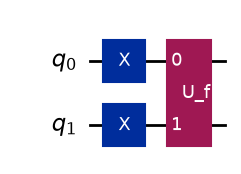

<IPython.core.display.Latex object>


Oráculo: balanceada_not_x


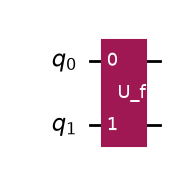

<IPython.core.display.Latex object>

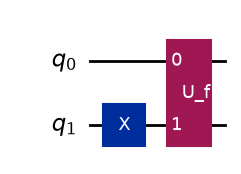

<IPython.core.display.Latex object>

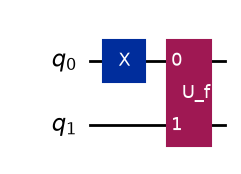

<IPython.core.display.Latex object>

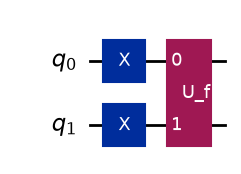

<IPython.core.display.Latex object>

In [93]:
# TODO: para cada oráculo y cada combinación (x, y):
# 1. Prepara el estado base.
# 2. Añade el oráculo.
# 3. Obtén el Statevector final.
# 4. Muestra x, y, f(x), y XOR f(x) y la etiqueta final.

for tipo in tipos_oraculo:
    print(f"\nOráculo: {tipo}")

    for x in [0, 1]:
        for y in [0, 1]:
            circuito = preparar_estado_base(x, y)
            oraculo = crear_oraculo_deutsch(tipo)
            circuito.append(oraculo, [0, 1])
            display(circuito.draw("mpl"))
            estado= Statevector.from_instruction(circuito)
            display(estado.draw("latex"))


### Tabla de resultados

Completa una tabla para cada oráculo:

| $x$ | $y$ | $f(x)$ | $y\oplus f(x)$ | Estado final |
|---:|---:|---:|---:|---|
| 0 | 0 |  |  |  |
| 0 | 1 |  |  |  |
| 1 | 0 |  |  |  |
| 1 | 1 |  |  |  |

### Respuestas del ejercicio 3

1. ¿Por qué debe interpretarse el estado de Qiskit como $\lvert q_1q_0\rangle$?
2. ¿Qué sucede al aplicar dos veces el mismo oráculo?
3. ¿Se recupera siempre el estado inicial?

**Respuesta:**  
Escribe aquí tu respuesta.




# Parte C. Algoritmo de Deutsch

## Ejercicio 4. Construcción del circuito

Construye el circuito siguiendo estas etapas:

1. Preparar $\lvert0\rangle\lvert1\rangle$.
2. Aplicar Hadamard a ambos qubits.
3. Aplicar el oráculo.
4. Aplicar Hadamard al qubit de entrada.
5. Medir únicamente el qubit de entrada.


In [71]:
def circuito_deutsch(tipo_oraculo, medir=True):
    '''
    Construye el algoritmo de Deutsch.

    q[0]: entrada
    q[1]: auxiliar
    c[0]: clasificación
    '''
    # TODO: crea el circuito con o sin bit clásico.
    # Añade barreras entre las etapas principales.
    pass


In [72]:
# TODO: visualiza los cuatro circuitos.
# for tipo in tipos_oraculo:
#     circuito = circuito_deutsch(tipo)
#     print(tipo)
#     display(circuito.draw("mpl"))


### Respuestas del ejercicio 4

1. ¿En qué estado queda el auxiliar después de las primeras puertas?
2. ¿Qué información introduce el oráculo?
3. ¿Qué función tiene la segunda Hadamard del qubit de entrada?
4. ¿Por qué no es necesario medir el auxiliar?

**Respuesta:**  
Escribe aquí tu respuesta.


## Ejercicio 5. Simulación exacta

Construye cada circuito sin medida y calcula las probabilidades marginales de `q[0]` mediante:

```python
estado.probabilities(qargs=[0])
```


In [73]:
resultados_exactos = {}

# TODO: calcula P(q0=0) y P(q0=1) para cada oráculo.
# Guarda los resultados en resultados_exactos y muéstralos.


Completa la tabla:

| Oráculo | $P(q_0=0)$ | $P(q_0=1)$ | Clasificación |
|---|---:|---:|---|
| `constante_0` |  |  |  |
| `constante_1` |  |  |  |
| `balanceada_x` |  |  |  |
| `balanceada_not_x` |  |  |  |


In [74]:
def interpretar_deutsch(probabilidades, tolerancia=1e-10):
    '''Interpreta las probabilidades ideales de q[0].'''
    # TODO: devuelve "constante" o "balanceada".
    # Rechaza resultados que no sean deterministas dentro de la tolerancia.
    pass


### Respuestas del ejercicio 5

1. ¿Producen el mismo vector de estado las dos funciones constantes?
2. ¿Producen el mismo resultado de medida?
3. ¿Qué diferencia puede existir aunque la clasificación coincida?
4. ¿Sucede algo semejante con las funciones balanceadas?
5. ¿El algoritmo identifica la función exacta o solamente su tipo?

**Respuesta:**  
Escribe aquí tu respuesta.


## Ejercicio 6. Simulación mediante shots

Implementa una función de ejecución con `AerSimulator`. Debe validar que `shots` sea un entero positivo, transpilar el circuito y devolver sus conteos.


In [75]:
def ejecutar_circuito(circuito, shots=1_000, semilla=42):
    '''Ejecuta un circuito con AerSimulator y devuelve los conteos.'''
    # TODO: valida shots, transpila, ejecuta y devuelve get_counts().
    pass


In [76]:
resultados_shots = {}

# TODO: ejecuta los cuatro circuitos con SHOTS medidas.
# Guarda y muestra los conteos.


In [77]:
# TODO: representa los cuatro histogramas.
# Puedes usar plot_histogram(conteos, title=...).


### Respuestas del ejercicio 6

1. ¿Coinciden los conteos con la simulación exacta?
2. ¿Existe variabilidad estadística en el simulador ideal para estos circuitos?
3. ¿Por qué todos los shots proporcionan el mismo resultado ideal?
4. ¿Sucedería necesariamente lo mismo en un computador cuántico real?

**Respuesta:**  
Escribe aquí tu respuesta.




# Parte D. Retroceso de fase

## Ejercicio 7. Observación del *phase kickback*

Prepara $\lvert x\rangle\lvert-\rangle$ para $x=0$ y $x=1$ y verifica:

$$
U_f\lvert x\rangle\lvert-\rangle
=(-1)^{f(x)}\lvert x\rangle\lvert-\rangle.
$$


In [78]:
def preparar_entrada_phase_kickback(x):
    '''Prepara |x>|-> con q[0] como entrada y q[1] como auxiliar.'''
    # TODO: valida x y prepara el circuito.
    pass


In [79]:
# TODO: para cada oráculo y x en {0, 1}:
# 1. Obtén el estado antes del oráculo.
# 2. Obtén el estado posterior.
# 3. Determina f(x) y el factor esperado (-1)**f(x).
# 4. Comprueba la igualdad con np.allclose().

resultados_phase_kickback = []


Completa la tabla:

| Oráculo | $x$ | $f(x)$ | Factor esperado | ¿Se cumple? |
|---|---:|---:|---:|---:|
| `constante_0` | 0 |  |  |  |
| `constante_0` | 1 |  |  |  |
| `constante_1` | 0 |  |  |  |
| `constante_1` | 1 |  |  |  |
| `balanceada_x` | 0 |  |  |  |
| `balanceada_x` | 1 |  |  |  |
| `balanceada_not_x` | 0 |  |  |  |
| `balanceada_not_x` | 1 |  |  |  |

### Respuestas del ejercicio 7

1. ¿Dónde queda codificado $f(x)$?
2. ¿Cambia el estado observable del auxiliar?
3. ¿Por qué una fase global aislada no puede medirse?
4. ¿Cómo se convierte una diferencia de fase en una diferencia observable?
5. ¿Qué papel desempeña la interferencia?

**Respuesta:**  
Escribe aquí tu respuesta.




# Parte E. Generalización a Deutsch–Jozsa

## Ejercicio 8. Oráculos de varios qubits

Construye oráculos para:

$$
f:\{0,1\}^n\longrightarrow\{0,1\}.
$$

Implementaremos una función constante cero, una constante uno y la función balanceada de paridad:

$$
f(x_0,\ldots,x_{n-1})=x_0\oplus\cdots\oplus x_{n-1}.
$$


In [80]:
def crear_oraculo_deutsch_jozsa(numero_entradas, tipo):
    '''
    Construye un oráculo constante o de paridad.

    El último qubit es el auxiliar.
    '''
    # TODO: valida numero_entradas y tipo.
    # TODO: implementa constante_0, constante_1 y paridad.
    pass


In [81]:
tipos_dj = ["constante_0", "constante_1", "paridad"]

# TODO: visualiza los tres oráculos para n=3.


### Respuestas del ejercicio 8

1. ¿Por qué la función de paridad es balanceada?
2. ¿Es la paridad la única función balanceada posible?
3. ¿Cuántos qubits necesita el oráculo para $n$ entradas?
4. ¿Cuántas puertas CNOT contiene el oráculo de paridad?

**Respuesta:**  
Escribe aquí tu respuesta.


## Ejercicio 9. Circuito de Deutsch–Jozsa

El circuito debe preparar el auxiliar en $\lvert1\rangle$, aplicar Hadamard a todos los qubits, utilizar una vez el oráculo, aplicar Hadamard al registro de entrada y medir únicamente dicho registro.


In [82]:
def circuito_deutsch_jozsa(numero_entradas, tipo_oraculo, medir=True):
    '''Construye el algoritmo de Deutsch-Jozsa.'''
    # TODO: implementa el circuito completo.
    pass


In [83]:
numero_entradas = 3
resultados_dj = {}

# TODO: visualiza y ejecuta los circuitos constante_0,
# constante_1 y paridad para n=3.


In [84]:
def interpretar_deutsch_jozsa(conteos, numero_entradas):
    '''Clasifica un oráculo a partir de conteos ideales.'''
    # TODO: valida los argumentos.
    # Si el único resultado es 00...0, devuelve "constante".
    # Si no, devuelve "balanceada".
    pass


Completa la tabla:

| Oráculo | Resultado ideal | Resultado simulado | Clasificación |
|---|---|---|---|
| `constante_0` |  |  |  |
| `constante_1` |  |  |  |
| `paridad` |  |  |  |

### Respuestas del ejercicio 9

1. ¿Qué resultado identifica una función constante?
2. ¿Qué resultado identifica una función balanceada?
3. ¿Por qué no es necesario conocer qué cadena no nula aparecerá?
4. ¿Qué importancia tiene la promesa del problema?

**Respuesta:**  
Escribe aquí tu respuesta.




# Parte F. Consulta clásica frente a consulta cuántica

## Ejercicio 10. Número de consultas

Para una función prometida constante o balanceada, un algoritmo clásico determinista exacto necesita en el peor caso:

$$
2^{n-1}+1
$$

consultas. Deutsch–Jozsa utiliza una consulta al oráculo ideal.


In [85]:
def consultas_clasicas(numero_entradas):
    # TODO: valida y devuelve el peor caso clásico.
    pass


def consultas_cuanticas(numero_entradas):
    # TODO: valida y devuelve el número de consultas cuánticas.
    pass


In [86]:
# TODO: completa una tabla para n = 1, 2, 3, 4, 5, 10 y 20.
valores_tabla = [1, 2, 3, 4, 5, 10, 20]


In [87]:
# TODO: representa las consultas clásicas y cuánticas para n entre 1 y 20.
# Usa escala logarítmica en el eje vertical.

valores_n = np.arange(1, 21)


### Respuestas del ejercicio 10

1. ¿Cómo crece el número clásico de consultas?
2. ¿Cómo crece el número cuántico de consultas?
3. ¿Significa esto que todo el circuito tiene coste constante?
4. ¿Qué costes no refleja el número de consultas?
5. ¿Contra qué tipo de algoritmo clásico se obtiene esta separación?

**Respuesta:**  
Escribe aquí tu respuesta.




# Parte G. Identificación de un oráculo desconocido

## Ejercicio 11. Caja negra

Ejecuta la siguiente celda una sola vez. La función elegirá uno de los cuatro oráculos. No muestres ni inspecciones el circuito interno del oráculo: utilízalo como una caja negra.


In [88]:
def obtener_oraculo_desconocido(semilla=2026):
    rng = np.random.default_rng(semilla)
    tipos = [
        "constante_0",
        "constante_1",
        "balanceada_x",
        "balanceada_not_x",
    ]
    tipo_secreto = tipos[int(rng.integers(0, len(tipos)))]
    return crear_oraculo_deutsch(tipo_secreto)


oraculo_desconocido = obtener_oraculo_desconocido()


In [89]:
def circuito_deutsch_con_oraculo(oraculo):
    '''Construye Deutsch a partir de una puerta de dos qubits.'''
    # TODO: construye el circuito sin inspeccionar el contenido del oráculo.
    pass


In [90]:
# TODO: ejecuta 1.000 shots, representa el histograma
# y clasifica la función desconocida.


### Respuestas del ejercicio 11

1. ¿La función desconocida es constante o balanceada? Justifica la respuesta.
2. ¿Podrías identificar la función exacta con este circuito?
3. ¿Qué información proporciona realmente la medida?
4. ¿Cuántas veces aparece el oráculo en el circuito?
5. ¿Cuántas ejecuciones se realizan al utilizar 1.000 shots?
6. ¿Por qué “una consulta al oráculo” y “1.000 shots” no son afirmaciones contradictorias?

**Respuesta:**  
Escribe aquí tu respuesta.
